# BlinkIT Grocery Sales Analysis
**Student Project | Sapphire IQ**

## Project objective
Analyze the supplied BlinkIT grocery dataset to understand sales performance by product, category, outlet, and location; assess data quality; and provide practical business recommendations.

### Tools
Python, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook

### Dataset
Expected file: `BlinkIT Grocery Data.xlsx` in the same folder as this notebook.

## 1. Import libraries and load the data
If needed, install packages with:
`pip install pandas numpy matplotlib seaborn openpyxl`

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
DATA_FILE = Path("BlinkIT Grocery Data.xlsx")

if not DATA_FILE.exists():
    raise FileNotFoundError(
        "Place 'BlinkIT Grocery Data.xlsx' in the same folder as this notebook."
    )

df = pd.read_excel(DATA_FILE)
print("Dataset loaded successfully")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully
Shape: (8523, 12)


,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


In [4]:
%pip install seaborn pandas numpy matplotlib openpyxl


Note: you may need to restart the kernel to use updated packages.


## 2. Understand the dataset

In [6]:
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes.to_frame("Data Type"))
print("\nSummary statistics:")
display(df.describe(include="all").T)

Rows and columns: (8523, 12)

Column names:
['Item Fat Content', 'Item Identifier', 'Item Type', 'Outlet Establishment Year', 'Outlet Identifier', 'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility', 'Item Weight', 'Sales', 'Rating']

Data types:


,Data Type
Item Fat Content,str
Item Identifier,str
Item Type,str
Outlet Establishment Year,int64
Outlet Identifier,str
Outlet Location Type,str
Outlet Size,str
Outlet Type,str
Item Visibility,float64
Item Weight,float64



Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Item Fat Content,8523,5,Low Fat,5089,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item Identifier,8523,1559,FDW13,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item Type,8523,16,Fruits and Vegetables,1232,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet Establishment Year,8523.0,NaN,NaN,NaN,2016.450546,3.189396,2011.0,2014.0,2016.0,2018.0,2022.0
Outlet Identifier,8523,10,OUT027,935,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet Location Type,8523,3,Tier 3,3350,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet Size,8523,3,Medium,3631,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet Type,8523,4,Supermarket Type1,5577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item Visibility,8523.0,NaN,NaN,NaN,0.066132,0.051598,0.0,0.026989,0.053931,0.094585,0.328391
Item Weight,7060.0,NaN,NaN,NaN,12.857645,4.643456,4.555,8.77375,12.6,16.85,21.35


## 3. Data quality assessment

In [7]:
quality = pd.DataFrame({
    "Missing Values": df.isna().sum(),
    "Missing %": (df.isna().mean() * 100).round(2),
    "Unique Values": df.nunique(),
    "Data Type": df.dtypes.astype(str)
})
display(quality)
print("Exact duplicate rows:", df.duplicated().sum())

,Missing Values,Missing %,Unique Values,Data Type
Item Fat Content,0,0.00,5,str
Item Identifier,0,0.00,1559,str
Item Type,0,0.00,16,str
Outlet Establishment Year,0,0.00,9,int64
Outlet Identifier,0,0.00,10,str
Outlet Location Type,0,0.00,3,str
Outlet Size,0,0.00,3,str
Outlet Type,0,0.00,4,str
Item Visibility,0,0.00,7880,float64
Item Weight,1463,17.17,415,float64


Exact duplicate rows: 0


## 4. Clean and standardize the data
- Standardize the fat-content labels (`LF`, `low fat`, and `Low Fat`; `reg` and `Regular`).
- Preserve the original dataset in `df`.
- Fill missing item weights using the median weight for the same item identifier when available, then use the overall median as a fallback. Since item weights may differ by item, this is a practical imputation approach, not a verified ground-truth recovery.
- Check for impossible/negative numeric values.

In [8]:
clean_df = df.copy()

# Standardize text categories
clean_df["Item Fat Content"] = (
    clean_df["Item Fat Content"].astype(str).str.strip().replace({
        "LF": "Low Fat",
        "low fat": "Low Fat",
        "reg": "Regular"
    })
)

# Numeric validation
numeric_cols = ["Item Visibility", "Item Weight", "Sales", "Rating"]
for col in numeric_cols:
    clean_df[col] = pd.to_numeric(clean_df[col], errors="coerce")

print("Negative values by numeric field:")
display((clean_df[numeric_cols] < 0).sum().to_frame("Negative Count"))

# Fill item weight using item-level median, then overall median
weight_by_item = clean_df.groupby("Item Identifier")["Item Weight"].transform("median")
clean_df["Item Weight"] = clean_df["Item Weight"].fillna(weight_by_item)
clean_df["Item Weight"] = clean_df["Item Weight"].fillna(clean_df["Item Weight"].median())

print("Missing values after cleaning:")
display(clean_df.isna().sum().to_frame("Missing Values"))
print("Fat content labels after standardization:")
display(clean_df["Item Fat Content"].value_counts())

Negative values by numeric field:


,Negative Count
Item Visibility,0
Item Weight,0
Sales,0
Rating,0


Missing values after cleaning:


,Missing Values
Item Fat Content,0
Item Identifier,0
Item Type,0
Outlet Establishment Year,0
Outlet Identifier,0
Outlet Location Type,0
Outlet Size,0
Outlet Type,0
Item Visibility,0
Item Weight,0


Fat content labels after standardization:


Item Fat Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64

## 5. Key performance indicators (KPIs)

In [9]:
total_sales = clean_df["Sales"].sum()
average_item_sales = clean_df["Sales"].mean()
average_rating = clean_df["Rating"].mean()
total_records = len(clean_df)
outlet_count = clean_df["Outlet Identifier"].nunique()
product_type_count = clean_df["Item Type"].nunique()

kpis = pd.DataFrame({
    "Metric": ["Total recorded sales", "Average sales per record", "Average rating",
               "Number of records", "Unique outlets", "Product categories"],
    "Value": [total_sales, average_item_sales, average_rating, total_records,
              outlet_count, product_type_count]
})
display(kpis.round(2))

,Metric,Value
0,Total recorded sales,1201681.49
1,Average sales per record,140.99
2,Average rating,3.97
3,Number of records,8523.00
4,Unique outlets,10.00
5,Product categories,16.00


## 6. Sales by product category

,Item Type,Sales
6,Fruits and Vegetables,178124.0810
13,Snack Foods,175433.9224
9,Household,135976.5254
5,Frozen Foods,118558.8814
4,Dairy,101276.4616
3,Canned,90706.7290
0,Baking Goods,81894.7364
8,Health and Hygiene,68025.8388
10,Meat,59449.8638
14,Soft Drinks,58514.1670


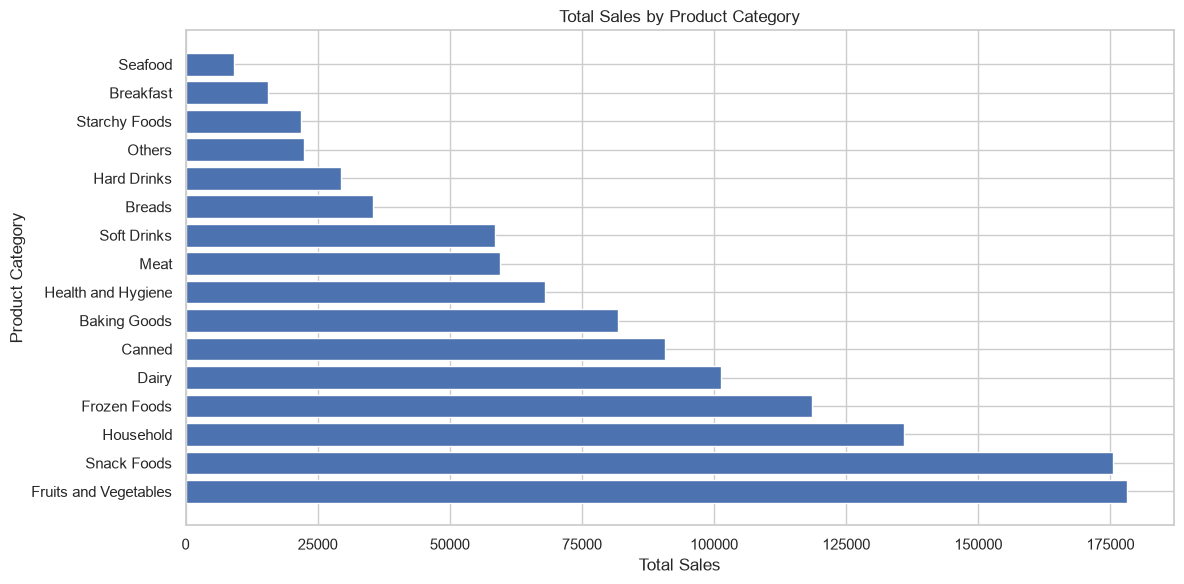

In [10]:
category_sales = clean_df.groupby("Item Type", as_index=False)["Sales"].sum().sort_values("Sales", ascending=False)
display(category_sales)
plt.figure(figsize=(12, 6))
plt.barh(category_sales["Item Type"], category_sales["Sales"])
plt.title("Total Sales by Product Category")
plt.xlabel("Total Sales")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

## 7. Sales by outlet type

,Outlet Type,Total_Sales,Average_Sales,Records
1,Supermarket Type1,787549.89,141.21,5577
0,Grocery Store,151939.15,140.29,1083
2,Supermarket Type2,131477.78,141.68,928
3,Supermarket Type3,130714.67,139.80,935


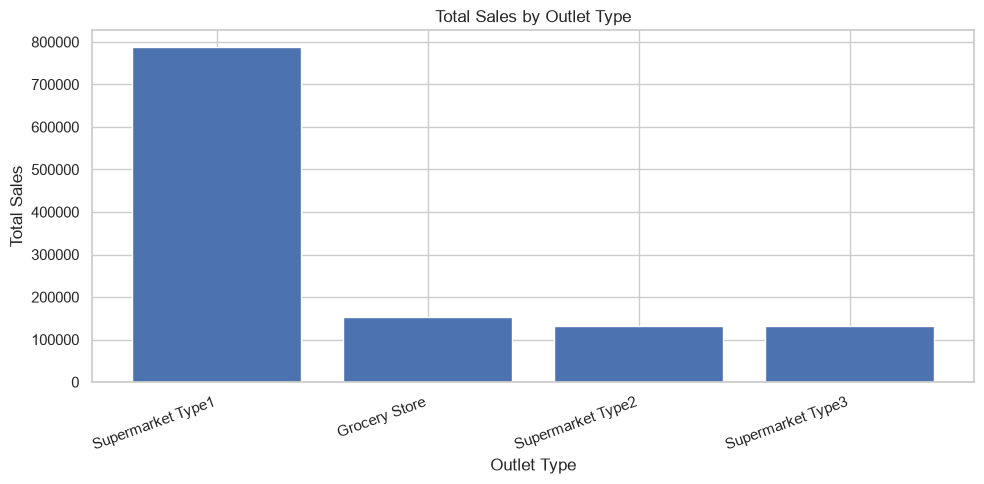

In [11]:
outlet_sales = clean_df.groupby("Outlet Type", as_index=False).agg(
    Total_Sales=("Sales", "sum"),
    Average_Sales=("Sales", "mean"),
    Records=("Sales", "size")
).sort_values("Total_Sales", ascending=False)
display(outlet_sales.round(2))
plt.figure(figsize=(10, 5))
plt.bar(outlet_sales["Outlet Type"], outlet_sales["Total_Sales"])
plt.title("Total Sales by Outlet Type")
plt.xlabel("Outlet Type")
plt.ylabel("Total Sales")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 8. Sales by outlet location and size

,Outlet Location Type,Sales
2,Tier 3,472133.0332
1,Tier 2,393150.6476
0,Tier 1,336397.8120


,Outlet Size,Sales
1,Medium,507895.7364
2,Small,444794.1704
0,High,248991.5860


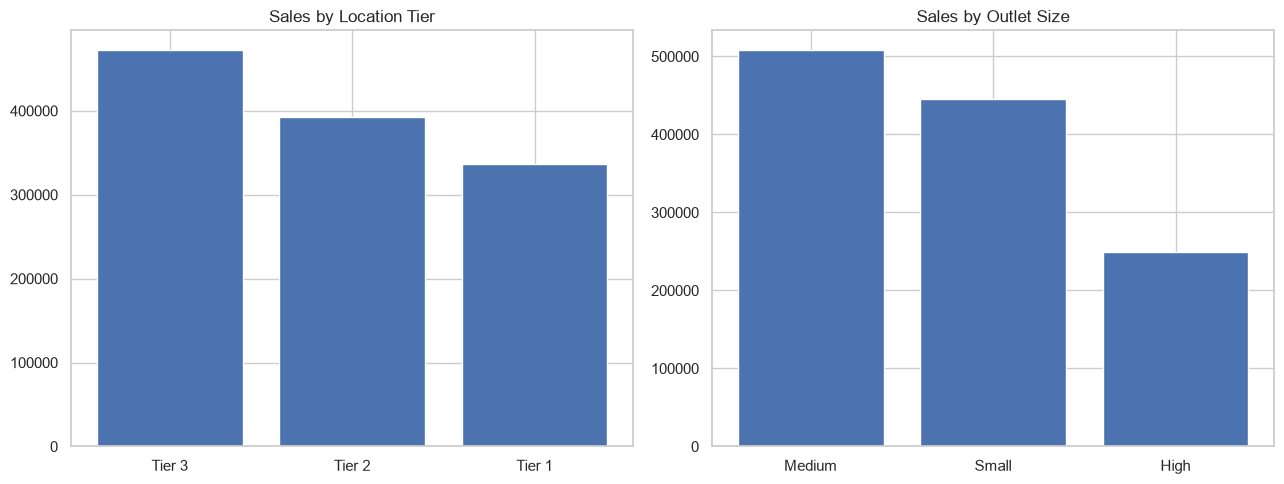

In [12]:
location_sales = clean_df.groupby("Outlet Location Type", as_index=False)["Sales"].sum().sort_values("Sales", ascending=False)
size_sales = clean_df.groupby("Outlet Size", as_index=False)["Sales"].sum().sort_values("Sales", ascending=False)
display(location_sales)
display(size_sales)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(location_sales["Outlet Location Type"], location_sales["Sales"])
axes[0].set_title("Sales by Location Tier")
axes[1].bar(size_sales["Outlet Size"], size_sales["Sales"])
axes[1].set_title("Sales by Outlet Size")
plt.tight_layout()
plt.show()

## 9. Fat content and product visibility

,Item Fat Content,Sales
0,Low Fat,776319.6884
1,Regular,425361.8044


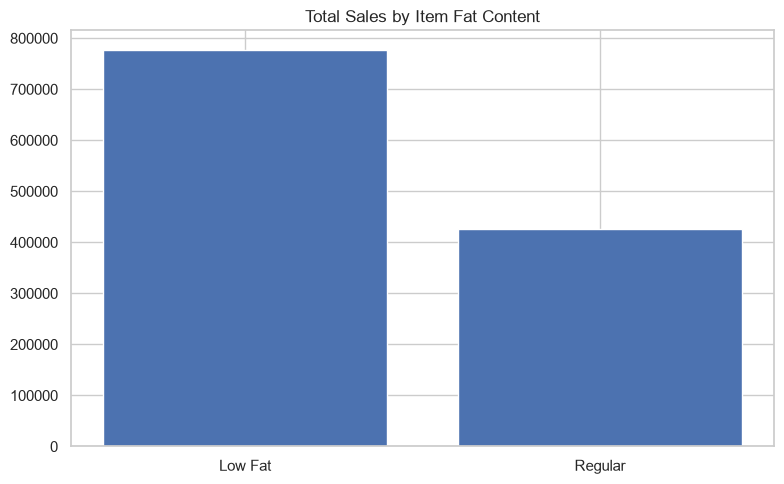

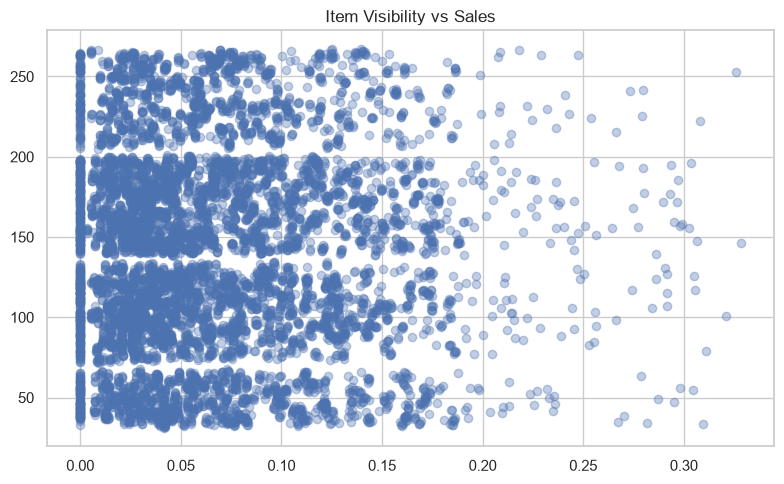

Correlation between visibility and sales: -0.001


In [13]:
fat_sales = clean_df.groupby("Item Fat Content", as_index=False)["Sales"].sum().sort_values("Sales", ascending=False)
display(fat_sales)

plt.figure(figsize=(8, 5))
plt.bar(fat_sales["Item Fat Content"], fat_sales["Sales"])
plt.title("Total Sales by Item Fat Content")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(clean_df["Item Visibility"], clean_df["Sales"], alpha=0.35)
plt.title("Item Visibility vs Sales")
plt.tight_layout()
plt.show()

print("Correlation between visibility and sales:",
      round(clean_df[["Item Visibility", "Sales"]].corr().iloc[0, 1], 3))

## 10. Rating and sales relationship

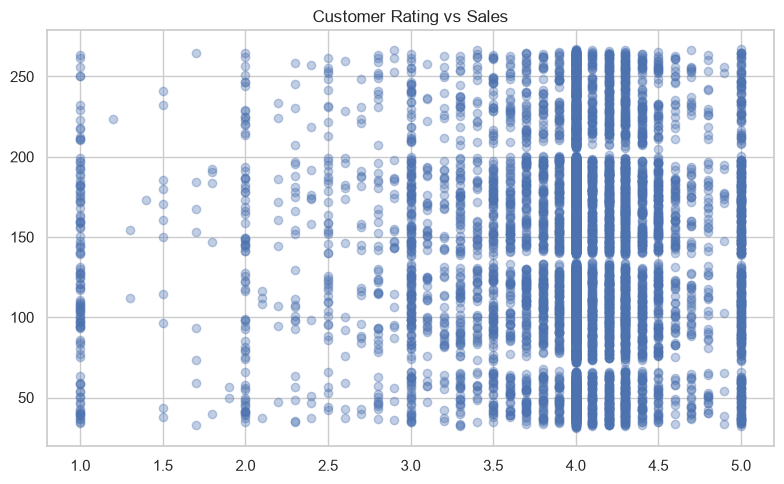

Correlation between rating and sales: 0.011


In [14]:
plt.figure(figsize=(8, 5))
plt.scatter(clean_df["Rating"], clean_df["Sales"], alpha=0.35)
plt.title("Customer Rating vs Sales")
plt.tight_layout()
plt.show()

print("Correlation between rating and sales:",
      round(clean_df[["Rating", "Sales"]].corr().iloc[0, 1], 3))

## 11. Outlet establishment year

,Outlet Establishment Year,Sales
0,2011,78131.5666
1,2012,130476.8598
2,2014,131809.0156
3,2015,130942.7802
4,2016,132113.3698
5,2017,133103.9070
6,2018,204522.2570
7,2020,129103.9604
8,2022,131477.7764


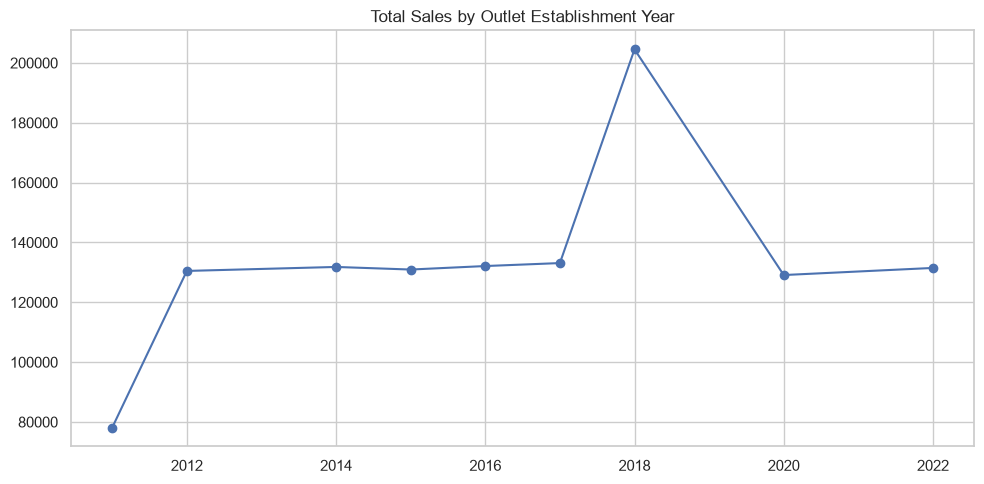

In [15]:
year_sales = clean_df.groupby("Outlet Establishment Year", as_index=False)["Sales"].sum().sort_values("Outlet Establishment Year")
display(year_sales)
plt.figure(figsize=(10, 5))
plt.plot(year_sales["Outlet Establishment Year"], year_sales["Sales"], marker="o")
plt.title("Total Sales by Outlet Establishment Year")
plt.tight_layout()
plt.show()

## 12. Automatic findings and recommendations

In [16]:
top_category = category_sales.iloc[0]
top_outlet = outlet_sales.iloc[0]
top_location = location_sales.iloc[0]
top_size = size_sales.iloc[0]
bottom_category = category_sales.iloc[-1]
visibility_corr = clean_df[["Item Visibility", "Sales"]].corr().iloc[0, 1]
rating_corr = clean_df[["Rating", "Sales"]].corr().iloc[0, 1]

print(f"Highest-sales category: {top_category['Item Type']} ({top_category['Sales']:,.2f})")
print(f"Highest-sales outlet type: {top_outlet['Outlet Type']} ({top_outlet['Total_Sales']:,.2f})")
print(f"Highest-sales location tier: {top_location['Outlet Location Type']} ({top_location['Sales']:,.2f})")
print(f"Highest-sales outlet size: {top_size['Outlet Size']} ({top_size['Sales']:,.2f})")
print(f"Lowest-sales category by total: {bottom_category['Item Type']} ({bottom_category['Sales']:,.2f})")
print(f"Visibility-sales correlation: {visibility_corr:.3f}")
print(f"Rating-sales correlation: {rating_corr:.3f}")

print("\nBusiness recommendations:")
print("1. Review inventory and shelf availability for high-contributing product categories.")
print("2. Compare outlet performance using both total sales and record counts; total sales alone may reflect outlet scale.")
print("3. Investigate lower-performing categories and outlets before changing assortment or promotions.")
print("4. Validate missing-weight imputation with source records if accurate item weights are operationally important.")
print("5. Treat correlations as associations, not proof that visibility or ratings cause higher sales.")

Highest-sales category: Fruits and Vegetables (178,124.08)
Highest-sales outlet type: Supermarket Type1 (787,549.89)
Highest-sales location tier: Tier 3 (472,133.03)
Highest-sales outlet size: Medium (507,895.74)
Lowest-sales category by total: Seafood (9,077.87)
Visibility-sales correlation: -0.001
Rating-sales correlation: 0.011

Business recommendations:
1. Review inventory and shelf availability for high-contributing product categories.
2. Compare outlet performance using both total sales and record counts; total sales alone may reflect outlet scale.
3. Investigate lower-performing categories and outlets before changing assortment or promotions.
4. Validate missing-weight imputation with source records if accurate item weights are operationally important.
5. Treat correlations as associations, not proof that visibility or ratings cause higher sales.


## 13. Export cleaned data and summary tables

In [18]:
clean_df.to_csv("BlinkIT_Cleaned_Data.csv", index=False)
category_sales.to_csv("BlinkIT_Sales_by_Category.csv", index=False)
outlet_sales.to_csv("BlinkIT_Sales_by_Outlet_Type.csv", index=False)
location_sales.to_csv("BlinkIT_Sales_by_Location.csv", index=False)
print("Exported cleaned data and summary tables to the current folder.")

Exported cleaned data and summary tables to the current folder.


## 14. Conclusion
This analysis reviews sales by category, outlet type, location, outlet size, fat content, visibility, rating, and establishment year. The charts and summary tables help identify areas for inventory planning and further investigation. Findings describe the supplied dataset; they should not be interpreted as causal claims or as company-wide facts beyond the data provided.

**Submission checklist**
- Run every notebook cell from top to bottom.
- Keep the Excel file beside the notebook.
- Review the generated charts and findings.
- Add your name, roll number, and submission date if required by your instructor.